# Local Matching for Wikidata

Finds duplicate records **within** the normalized Wikidata airport dataset (`wikidataNormalized.csv`): the same real-world airport stored as more than one row.

Candidate pairs are generated by two complementary blocking rules, and the union of their candidates is scored:

- **Rule A: `countryCode` + distinguishing `name` token.** Two records are candidates if they are in the same country and share a `name` token that is not a common word (airport, ranch, common surnames, ...). Needs a `countryCode` and at least one distinguishing token.
- **Rule B: geographic grid (H3).** Two records are candidates if they lie in the same or in adjacent H3 cells, regardless of name or country. Needs coordinates. It reaches records with generic names (e.g. `"smith ranch airport"`) or a missing `countryCode`.

A pair only needs to be found by one of the two rules.

**Steps**

1. Load the normalized dataset
2. Blocking Rule A: `countryCode` + distinguishing `name` tokens
3. Blocking Rule B: geographic grid (H3)
4. Combine and filter candidates: union of both rules, no self-pairs, no reversed duplicates
5. Coverage check: records reached by neither rule
6. Per-attribute comparators (name, city, geo distance, icao, iata)
7. Score candidates with `RuleBasedMatcher`
8. Score distribution
9. Manual review of high-scoring candidates

Note: `countryCode` + `city` and a `BallTree` radius search were also tried as alternatives to Rule B (see the note in the Rule B section).

**Known gap:** records that neither rule can reach (no `countryCode` or no distinguishing name token for Rule A, **and** no coordinates for Rule B) can never appear in a candidate pair. They are listed in the coverage check and accepted: there is not enough signal for any automated approach.

**Not done yet:** deciding how to resolve the duplicates found (merge, flag, remove, ...).

In [43]:
from pathlib import Path
from PyDI.entitymatching import TokenBlocker
from PyDI.entitymatching import RuleBasedMatcher
import matplotlib.pyplot as plt
import pandas as pd

## Load the normalized dataset (shared by all groups)

In [1]:
DATA_DIR = Path("../../data/normalized_outputs")
INPUT_CSV = DATA_DIR / "wikidataNormalized.csv"

df = pd.read_csv(INPUT_CSV, keep_default_na=False, na_values=[""])
df.attrs["source"] = "wikidata"

print(f"Loaded {len(df)} records")
print(f"Columns: {list(df.columns)}")
df.head(5)

Loaded 24859 records
Columns: ['id', 'name', 'iata', 'icao', 'lat', 'lon', 'elevation', 'countryName', 'city', 'wikidataURI', 'operator', 'timezone', 'owner', 'localCode', 'countryCode']


,id,name,iata,icao,lat,lon,elevation,countryName,city,wikidataURI,operator,timezone,owner,localCode,countryCode
0,wd_1,jian jinggangshan airport,JGS,ZSGS,26.857500,114.737222,86.0000,peoples republic of china,taihe county,http://www.wikidata.org/entity/Q1000018,NaN,NaN,NaN,NaN,CN
1,wd_2,changde taohuayuan airport,CGD,ZGCD,28.918900,111.640000,NaN,peoples republic of china,hunan,http://www.wikidata.org/entity/Q1000025,NaN,NaN,NaN,NaN,CN
2,wd_3,jiujiang lushan airport,JIU,ZSJJ,29.476944,115.801111,49.9872,peoples republic of china,jiujiang,http://www.wikidata.org/entity/Q1002604,NaN,NaN,NaN,NaN,CN
3,wd_4,aksu hongqipo airport,AKU,ZWAK,41.262500,80.291667,1163.0000,peoples republic of china,hongqipo,http://www.wikidata.org/entity/Q1006478,NaN,NaN,NaN,NaN,CN
4,wd_5,mohe gulian airport,OHE,ZYMH,52.921111,122.420556,579.0000,peoples republic of china,heilongjiang,http://www.wikidata.org/entity/Q1006900,NaN,NaN,NaN,NaN,CN


## Blocking Rule A: `countryCode` + distinguishing `name` tokens

- Goal: generate candidate duplicate pairs by self-blocking (the dataset against itself). Generic words in `name` (`airport`, `ranch`, common surnames, ...) and the unreliable `city` field (often a state or province, not a real city) must not be used as blocking keys, because they would put thousands of unrelated records into the same block.

- Method: `TokenBlocker` on `name`.
  - Tokens that appear in more than `COMMON_TOKEN_THRESHOLD` distinct names are treated as non-distinguishing and excluded; this list is derived from the data (document frequency).
  - `countryCode` is prepended to each remaining token (e.g. `"CN::jian"`), so a pair is a candidate only if the two records share a distinguishing token **and** have the same country.

- Limitation: records whose name has no distinguishing token left, or that have no `countryCode`, produce no tokens and cannot be found by this rule. They are covered by Rule B (geographic grid), whose candidates are combined with those of Rule A.


### Generate blocking key column

In [26]:
# Hand-picking generic words (airport, international, ...) was not enough: common
# rural/geographic filler words (ranch: 1084 rows, lake: 395, creek: 254, ...) and common
# surnames (smith, johnson, williams, ...) are just as damaging to block sizes.
# Instead, derive the exclusion list straight from the data: any token that appears in
# more than COMMON_TOKEN_THRESHOLD distinct names is treated as non-distinguishing.

from collections import Counter

COMMON_TOKEN_THRESHOLD = 20  # trade-off between threshold and number of common words

token_doc_freq = Counter()

for name in df["name"].dropna():
    token_doc_freq.update(set(t for t in name.split() if len(t) >= 2))

COMMON_TOKENS = {t for t, c in token_doc_freq.items() if c > COMMON_TOKEN_THRESHOLD}
print(f"Excluding {len(COMMON_TOKENS)} tokens that each appear in more than {COMMON_TOKEN_THRESHOLD} names")

def blocking_tokenizer(text):
    if not isinstance(text, str):
        return []
    return [t for t in text.split() if len(t) >= 2 and t not in COMMON_TOKENS]

sample_tokens = df["name"].dropna().head(5).apply(blocking_tokenizer)

print("\nExample tokens kept for blocking:")

for name, toks in zip(df["name"].dropna().head(5), sample_tokens):
    print(f"  {name!r:40s} -> {toks}")

no_tokens_left = df["name"].apply(lambda n: len(blocking_tokenizer(n)) == 0)

print(f"\n{no_tokens_left.sum()} records ({no_tokens_left.mean():.1%}) have no distinguishing token left "
      "and cannot be reached by Rule A. They can still be found by Rule B (geographic grid) if they have coordinates.")

Excluding 152 tokens that each appear in more than 20 names

Example tokens kept for blocking:
  'jian jinggangshan airport'              -> ['jian', 'jinggangshan']
  'changde taohuayuan airport'             -> ['changde', 'taohuayuan']
  'jiujiang lushan airport'                -> ['jiujiang', 'lushan']
  'aksu hongqipo airport'                  -> ['aksu', 'hongqipo']
  'mohe gulian airport'                    -> ['mohe', 'gulian']

1075 records (4.3%) have no distinguishing token left and cannot be reached by Rule A. They can still be found by Rule B (geographic grid) if they have coordinates.


### Implement Blocking to generate candidate pairs

In [28]:
# Combine countryCode into the blocking text so a single TokenBlocker call enforces
# "same country AND shares a distinguishing word" -- see Rule A markdown.
# A record with no countryCode or no name gets None -> no tokens -> can't be blocked

def make_blocking_text(row):
    if pd.isna(row["countryCode"]) or pd.isna(row["name"]):
        return None
    return f"{row['countryCode']}||{row['name']}"

df["name_with_country"] = df.apply(make_blocking_text, axis=1)

def country_scoped_tokenizer(text):
    if not isinstance(text, str):
        return []
    country, _, name = text.partition("||")
    return [f"{country}::{t}" for t in blocking_tokenizer(name)]

blocker_token = TokenBlocker(
    df_left=df,
    df_right=df,
    column="name_with_country",
    id_column="id",
    tokenizer=country_scoped_tokenizer,
)

candidates_token = blocker_token.materialize()
print(f"Raw candidate pairs from token blocking: {len(candidates_token)}")
print(blocker.stats())
candidates.head(10)

Raw candidate pairs from token blocking: 78376
{'pairs_emitted': 78376, 'batches_emitted': 1, 'batch_size': 100000}


,id1,id2
0,wd_1,wd_1
1,wd_2,wd_2
2,wd_3,wd_3
3,wd_4,wd_4
4,wd_5,wd_5
5,wd_6,wd_6
6,wd_7,wd_7
7,wd_8,wd_8
8,wd_9,wd_9
9,wd_10,wd_10


### Deduplication of pairs
- Goal: remove the noise self-blocking produces. 
- Method: drop `id1 == id2`, and keep one canonical direction per pair (`id1 < id2`) to drop `(A,B)`/`(B,A)` duplicates.

In [29]:
# Drop self-pairs
candidates_token = candidates_token[candidates_token["id1"] != candidates_token["id2"]].copy()

# Keep one canonical direction per pair (id1 < id2) to drop reversed duplicates
swap = candidates_token["id1"] > candidates_token["id2"]
candidates_token.loc[swap, ["id1", "id2"]] = candidates_token.loc[swap, ["id2", "id1"]].values
candidates_token = candidates_token.drop_duplicates(subset=["id1", "id2"])

candidates_token = candidates_token.reset_index(drop=True)
print(f"Candidate pairs after filtering: {len(candidates_token)}")
candidates.head(10)

Candidate pairs after filtering: 27306


,id1,id2
0,wd_1,wd_1
1,wd_2,wd_2
2,wd_3,wd_3
3,wd_4,wd_4
4,wd_5,wd_5
5,wd_6,wd_6
6,wd_7,wd_7
7,wd_8,wd_8
8,wd_9,wd_9
9,wd_10,wd_10


## Blocking Rule B: Geographic grid (H3)

- Goal: find duplicate pairs that Rule A (`countryCode` + distinguishing name token) cannot reach, i.e. records whose names are generic or share no distinguishing token, or whose `countryCode` is missing. Any two records that lie close to each other become candidates, regardless of their names or country labels.

- Method: map each record to an [H3](https://h3geo.org/) hexagonal cell at resolution `RESOLUTION` (average edge length ≈ `<X>` km) and use `TokenBlocker` the same way as in Rule A, except that the "tokens" are H3 cell IDs.
  - Each record emits **7 tokens**: the cell containing it plus its 6 neighboring cells (`h3.grid_disk(cell, 1)`). Two records that fall into the same or adjacent cells therefore always share a token, so pairs split by a cell border are not lost. Two points closer than about one cell edge are always in the same or adjacent cells.
  - `countryCode` is deliberately **not** part of the token. Within a cell of this size the country check adds almost no pruning, and omitting it also covers records with a missing or inconsistent `countryCode` (e.g. historical or disputed territories).
  - Records without coordinates emit no tokens and cannot be reached by this rule (known gap: 51 records).

- Implementation note: `TokenBlocker`'s tokenizer only sees the text of a single column, but the grid needs both `lat` and `lon`. The tokens are therefore precomputed per record and looked up by `id`, with the `id` itself serving as the blocking "text" column.

- Candidates of Rule A and Rule B are combined by union and de-duplicated (see below), so a pair only needs to be found by one of the two rules. Whether the `countryCode` of a candidate pair agrees is left to the scoring step.


### Define H3 grid token generation function

In [30]:
import h3
RESOLUTION = 9

def geo_h3_tokens(row):
    if pd.isna(row["lat"]) or pd.isna(row["lon"]):
        return []

    # * get the h3 grid id for the coordinate
    center = h3.latlng_to_cell(row["lat"], row["lon"], RESOLUTION) 

    # * return the grid plus other six proximate hexagons (in total, 7 ids)
    return list(h3.grid_disk(center, 1))

print(f"Test the behavior. Input: (25,0215, 121,5637)")
set(geo_h3_tokens({"lat": 25.0215, "lon": 121.5637}))

Test the behavior. Input: (25,0215, 121,5637)


{'894ba0a4a8bffff',
 '894ba0a4a9bffff',
 '894ba0a4ac3ffff',
 '894ba0a4ac7ffff',
 '894ba0a4ad3ffff',
 '894ba0a4ad7ffff',
 '894ba0a4e6fffff'}

### Generate blocking key `geo_grid_tokens` column


In [31]:
# TokenBlocker's tokenizer only sees one column's text, so precompute the 7 H3 cell IDs
# per record and look them up by id (the "text" column is just each record's own id).
df["geo_grid_tokens"] = df.apply(geo_h3_tokens, axis=1)
grid_token_lookup = df.set_index("id")["geo_grid_tokens"].to_dict()

### Implement Blocking to generate candidate pairs

In [32]:
# * define grid tokenizer
def grid_tokenizer(record_id):
    return grid_token_lookup.get(record_id, [])

df["id_as_text"] = df["id"]

blocker_geo = TokenBlocker(
    df_left=df,
    df_right=df,
    column="id_as_text",
    id_column="id",
    tokenizer=grid_tokenizer,
)


### Deduplication of pairs
- Goal: remove the noise self-blocking produces. 
- Method: drop `id1 == id2`, and keep one canonical direction per pair (`id1 < id2`) to drop `(A,B)`/`(B,A)` duplicates.

In [33]:

candidates_geo = blocker_geo.materialize()
print(f"Raw candidate pairs: {len(candidates_geo)}")

candidates_geo = candidates_geo[candidates_geo["id1"] != candidates_geo["id2"]].copy()
swap = candidates_geo["id1"] > candidates_geo["id2"]
candidates_geo.loc[swap, ["id1", "id2"]] = candidates_geo.loc[swap, ["id2", "id1"]].values
candidates_geo = candidates_geo.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"Candidate pairs after filtering: {len(candidates_geo)}") 


Raw candidate pairs: 25406
Candidate pairs after filtering: 299


## Concatenate candidate pairs from two blocking rules

In [37]:
candidates = pd.concat([candidates_geo, candidates_token], axis = 0)

# pair dedup
candidates = candidates[candidates["id1"] != candidates["id2"]].copy()
swap = candidates["id1"] > candidates["id2"]
candidates.loc[swap, ["id1", "id2"]] = candidates.loc[swap, ["id2", "id1"]].values
candidates = candidates.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"All candidate pairs after deduplication: {len(candidates)}") 

All candidate pairs after deduplication: 27476


In [38]:
def pair_set(df_pairs):
    d = df_pairs[df_pairs["id1"] != df_pairs["id2"]]
    return set(zip(d[["id1", "id2"]].min(axis=1), d[["id1", "id2"]].max(axis=1)))

s_token, s_geo = pair_set(candidates_token), pair_set(candidates_geo)
print(f"Rule A: {len(s_token)} | Rule B: {len(s_geo)} | both: {len(s_token & s_geo)} | union: {len(s_token | s_geo)}")

Rule A: 27306 | Rule B: 299 | both: 129 | union: 27476


## Implement Local Matching

Given the candidate pairs produced by Rule A and Rule B, we score each pair and review the high-scoring ones.

### Define comparators for relevant attributes

Goal: a similarity score per attribute for each candidate pair.

Method:

- `name`, `city`: Jaro-Winkler string similarity. Note that the built-in `StringComparator` returns `0.0` if either value is missing (this applies to 1.5% of the records for `city`); we accept this because `city` has a low weight.
- `lat`/`lon`: one `GeoDistanceComparator` (Haversine great-circle distance, `max_distance_km=2.0`), not two independent degree-difference comparators, because degrees of longitude shrink with latitude and this dataset has high-latitude airports. `2 km` (not a looser value like 50 km) because known-different airports in this dataset sit 2-5 km apart and would otherwise still score 0.90+.
- `icao`, `iata`: custom `CodeComparator`: exact match, but neutral (`0.5`) when either side is missing, instead of the built-in `StringComparator`'s `0.0` (which would treat "no code recorded" as "confidently not a duplicate").


In [39]:
import math

from PyDI.entitymatching import StringComparator
from PyDI.entitymatching.base import BaseComparator

# name: tolerant of small spelling differences
name_comp = StringComparator(column="name", similarity_function="jaro_winkler")

# city: same metric, weighted lower later (see markdown above)
city_comp = StringComparator(column="city", similarity_function="jaro_winkler")

# lat/lon: great-circle (Haversine) distance between the two points, not two
# independent degree-difference comparators (see markdown above for why).
class GeoDistanceComparator(BaseComparator):
    """Great-circle (Haversine) distance between two lat/lon points, converted to similarity."""

    def __init__(self, lat_column="lat", lon_column="lon", max_distance_km=10.0):
        super().__init__(name="geo_distance")
        self.lat_column = lat_column
        self.lon_column = lon_column
        self.max_distance_km = max_distance_km

    def compare(self, record1, record2):
        lat1, lon1 = record1.get(self.lat_column), record1.get(self.lon_column)
        lat2, lon2 = record2.get(self.lat_column), record2.get(self.lon_column)
        if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
            return 0.5  # neutral: can't compute without both coordinates
        distance_km = self._haversine_km(lat1, lon1, lat2, lon2)
        return max(0.0, 1.0 - distance_km / self.max_distance_km)

    @staticmethod
    def _haversine_km(lat1, lon1, lat2, lon2):
        R = 6371.0  # Earth radius in km
        phi1, phi2 = math.radians(lat1), math.radians(lat2)
        dphi = math.radians(lat2 - lat1)
        dlambda = math.radians(lon2 - lon1)
        a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
        return 2 * R * math.asin(math.sqrt(a))

geo_comp = GeoDistanceComparator(max_distance_km=2.0)

# iata/icao: custom comparator with neutral handling of missing values
# (see markdown above for why the built-in StringComparator is not used here).
# RuleBasedMatcher calls `comparator.compare(record1, record2)` directly, so this
# must subclass BaseComparator -- a plain function would not work here.

class CodeComparator(BaseComparator):
    """Exact-match comparator for a code column (iata/icao), neutral on missing values."""

    def __init__(self, column):
        super().__init__(name=f"{column}_exact")
        self.column = column

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if pd.isna(v1) or pd.isna(v2):
            return 0.5  # neutral: no evidence either way
        return 1.0 if v1 == v2 else 0.0

icao_comp = CodeComparator("icao")
iata_comp = CodeComparator("iata")

comparators = [name_comp, city_comp, geo_comp, icao_comp, iata_comp]
comparator_names = ["name", "city", "geo_distance", "icao", "iata"]

# Quick sanity check: compare the first candidate pair field by field
row = candidates.iloc[0]
r1 = df.set_index("id").loc[row["id1"]]
r2 = df.set_index("id").loc[row["id2"]]
for cname, comp in zip(comparator_names, comparators):
    print(f"  {cname:<12} -> {comp.compare(r1, r2):.2f}")

  name         -> 0.70
  city         -> 1.00
  geo_distance -> 1.00
  icao         -> 0.50
  iata         -> 0.50


### Score candidates with `RuleBasedMatcher`

Goal: combine the per-attribute scores into one score per candidate pair.

Method: weighted sum of the five comparator scores. The weights sum to 1.0, so the final score lies in [0, 1].

| Attribute | Weight | Rationale |
|---|---|---|
| `name` | 0.35 | Most discriminative attribute available for almost every record |
| `geo_distance` | 0.30 | Duplicates of the same airport lie very close to each other (`max_distance_km=2.0`) |
| `icao` | 0.15 | Strong when present on both sides; neutral (`0.5`) when missing |
| `iata` | 0.10 | Same as `icao`, but less often available |
| `city` | 0.10 | Lowest: in Wikidata it is often a county or state rather than a real city |

`threshold=0.0` keeps every candidate pair for now. The actual cutoff is chosen from the score distribution in the next step instead of being guessed.


In [41]:
weights = [0.35, 0.10, 0.30, 0.15, 0.10]  # name, city, geo_distance, icao, iata

matcher = RuleBasedMatcher()
correspondences, debug_results = matcher.match(
    df_left=df,
    df_right=df,
    candidates=candidates[["id1", "id2"]],
    id_column="id",
    comparators=comparators,
    weights=weights,
    threshold=0.0,  # keep everything for now
    debug=True,
)

print(f"Scored {len(correspondences)} candidate pairs")
correspondences.head(10)

Scored 27476 candidate pairs


,id1,id2,score,notes
0,wd_20389,wd_61,0.769982,comparators=5
1,wd_18942,wd_205,0.727773,comparators=5
2,wd_206,wd_22412,0.746154,comparators=5
3,wd_17750,wd_212,0.692382,comparators=5
4,wd_19761,wd_354,0.609853,comparators=5
5,wd_20729,wd_359,0.694587,comparators=5
6,wd_389,wd_5625,0.673571,comparators=5
7,wd_17437,wd_402,0.505855,comparators=5
8,wd_409,wd_6681,0.702778,comparators=5
9,wd_20402,wd_447,0.762759,comparators=5


### Score distribution

- Goal: see whether there's a natural gap between likely duplicates and likely blocking false positives before picking a threshold. 

- Method: histogram of all candidate scores.

count    27476.000000
mean         0.440847
std          0.066790
min          0.201193
25%          0.402667
50%          0.440163
75%          0.483493
max          0.865882
Name: score, dtype: float64


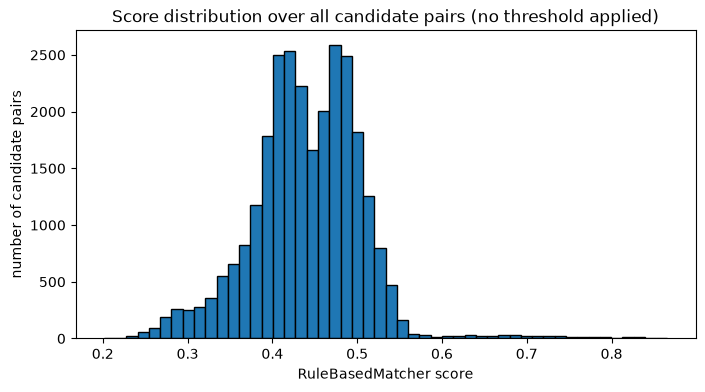

In [42]:
print(correspondences["score"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(correspondences["score"], bins=50, edgecolor="black")
ax.set_xlabel("RuleBasedMatcher score")
ax.set_ylabel("number of candidate pairs")
ax.set_title("Score distribution over all candidate pairs (no threshold applied)")
plt.show()

## Manual review of high-scoring candidates

- Goal: check whether the matcher's top-scoring pairs are real duplicates.

- Method: list every candidate with `score > 0.6` alongside `name`/`city`/`icao`/`iata` for manual inspection.

- Threshold: `0.6` was chosen from known cases (with `geo_distance` at 2 km, see the comparators section): known likely duplicates score 0.75-0.78, known non-duplicates score 0.45-0.49, so `0.6` sits in between with margin on both sides. The score distribution of the combined candidates (Rule A and Rule B) is consistent with this choice.


In [46]:
SCORE_THRESHOLD = 0.6

name_city_icao = df.set_index("id")[["name", "city", "icao", "iata"]]

review = (
    correspondences[correspondences["score"] > SCORE_THRESHOLD]
    .sort_values("score", ascending=False)
    .join(name_city_icao.add_suffix("1"), on="id1")
    .join(name_city_icao.add_suffix("2"), on="id2")
)

print(f"{len(review)} candidate pairs with score > {SCORE_THRESHOLD}")
review[["id1", "id2", "name1", "name2", "city1", "city2", "icao1", "icao2", "iata1", "iata2", "score"]].head(10)

379 candidate pairs with score > 0.6


,id1,id2,name1,name2,city1,city2,icao1,icao2,iata1,iata2,score
159,wd_11146,wd_23274,hickory ridge airport,hickory ridge airport,jefferson county,jefferson county,NaN,NaN,NaN,NaN,0.865882
171,wd_11572,wd_11574,ken guidry nr 1 airport,ken guidry number 1 airport,vermilion parish,vermilion parish,NaN,NaN,NaN,NaN,0.862798
252,wd_18175,wd_23311,diamond star ranch airport,diamond star ranch airport,huerfano county,huerfano county,NaN,NaN,NaN,NaN,0.858324
148,wd_10465,wd_23395,five oaks estate airport,five oaks estate airport,okaloosa county,okaloosa county,NaN,NaN,NaN,NaN,0.855561
208,wd_13401,wd_23479,rhea rla airport,rhea rla airport,hancock county,hancock county,NaN,NaN,NaN,NaN,0.852465
162,wd_11209,wd_23439,hobby hill airport,hobby hill airport,marion county,marion county,NaN,NaN,NaN,NaN,0.851087
267,wd_19091,wd_23323,marshdale airport,marshdale airport,jefferson county,jefferson county,NaN,NaN,NaN,NaN,0.849646
131,wd_23419,wd_9590,buddys ag service airport,buddys ag service airport,suwannee county,suwannee county,NaN,NaN,NaN,NaN,0.849636
49,wd_1928,wd_20341,captain luis f gomez nino air base,captain luis f gomez nino air base,meta,meta,NaN,SKAP,NaN,API,0.843256
264,wd_18718,wd_23595,iberlin ranch airport nr 1,iberlin ranch nr 1 airport,campbell county,campbell county,NaN,NaN,NaN,NaN,0.843012


### Coverage check: records reached by neither blocking rule

- Goal: find out which records cannot appear in any candidate pair, i.e. duplicates of them can never be detected.

- Method: a record is unreachable if
    - it cannot be reached by Rule A, which needs both a `countryCode` and at least one distinguishing `name` token, **and**
    - it cannot be reached by Rule B, which needs coordinates (`lat` and `lon`).

Records that fail only one of the two conditions are still covered by the other rule. The few records that fail both are listed below and accepted as a known gap: there is not enough signal for any automated approach.


In [48]:
not_by_rule_a = no_tokens_left | df["countryCode"].isna()
not_by_rule_b = df[["lat", "lon"]].isna().any(axis=1)

uncovered = not_by_rule_a & not_by_rule_b
print(uncovered.sum())
print(df.loc[uncovered, ["id", "name", "countryCode", "lat", "lon"]])


1
           id                                    name countryCode  lat  lon
2161  wd_2162  nagaki ruzaphema international airport         NaN  NaN  NaN
